# Faster R-CNN 逐阶段拆解（VGG16）

> 对应论文：*Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks* (NeurIPS 2015)


这份 notebook 把完整模型拆成 7 个可以单独运行的阶段。每个阶段先解释论文里的设计，再定义一小块代码，最后用合成图片显示中间张量的形状或可视化结果。

| 阶段 | 内容 | 关键问题 |
|---|---|---|
| 0 | 输入与配置 | 一张图如何变成张量？ |
| 1 | VGG16 共享主干 | `conv5_3` 的特征图有多大？ |
| 2 | Anchor | 9 个 anchor 如何覆盖多尺度、多长宽比？ |
| 3 | RPN | 如何从特征图得到 proposals？ |
| 4 | RoI head | 如何把不同大小的 proposal 变成 7×7 特征？ |
| 5 | 完整模型 | 四个 loss 分别从哪里来？ |
| 6 | 训练与反向传播 | 梯度是否流经共享主干？ |
| 7 | 推理与 NMS | 如何从 300 个 proposal 得到最终检测框？ |

> **注意**：notebook 里的模型默认是随机初始化。所有检测框的可视化只用于观察“数据流”，不代表真实检测效果。要看真实效果，需要在 VOC/COCO 上训练，或加载预训练权重。

## 0. 环境、随机种子与绘图工具

先确认 PyTorch、torchvision、Matplotlib 可用。后面的实验固定随机种子，方便重复观察。

In [4]:
import gc
import math
import random
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import nms, roi_pool

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

torch.manual_seed(0)
random.seed(0)
torch.set_printoptions(precision=3, sci_mode=False)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)


def to_numpy_image(image: torch.Tensor):
    """[3,H,W] in [0,1] -> [H,W,3] numpy，供 matplotlib 显示。"""
    return image.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()


def draw_box(ax, box, color="tab:blue", linewidth=1.4, linestyle="-",
             label=None, alpha=0.9):
    """在 matplotlib 坐标轴上画一个 xyxy 框。"""
    x1, y1, x2, y2 = [float(v) for v in box]
    ax.add_patch(
        plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor=color,
            linewidth=linewidth,
            linestyle=linestyle,
            label=label,
            alpha=alpha,
        )
    )


def draw_boxes(ax, boxes, color="tab:blue", linewidth=1.2, linestyle="-",
               labels=None, alpha=0.9):
    for i, box in enumerate(boxes):
        label = labels[i] if labels is not None else None
        draw_box(
            ax,
            box,
            color=color,
            linewidth=linewidth,
            linestyle=linestyle,
            label=label,
            alpha=alpha,
        )

PyTorch : 2.11.0+cu128
Device  : cuda


## 0.1 构造一张合成图

为了让后面的 feature map、anchor 和检测框能画在同一张图上，这里不用随机噪声，而是画两个简单的彩色矩形，并给它们配上 GT 框。

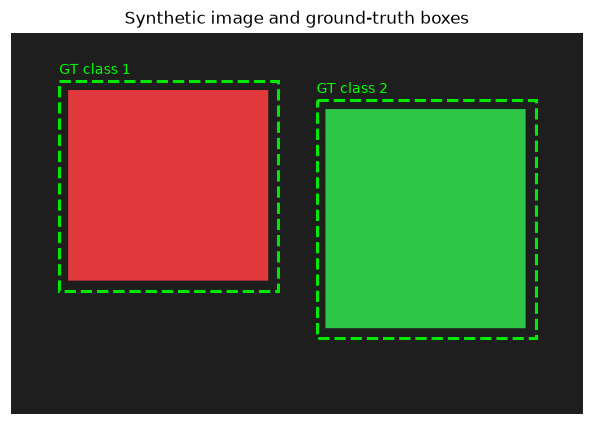

image tensor : (3, 320, 480) torch.float32
GT boxes     : (2, 4)
GT labels    : [1, 2]


In [5]:
H, W = 320, 480

image = torch.full((3, H, W), 0.12)
# 左边：偏红色的目标
image[0, 48:208, 48:216] = 0.88
image[1, 48:208, 48:216] = 0.22
image[2, 48:208, 48:216] = 0.24
# 右边：偏绿色的目标
image[0, 64:248, 264:432] = 0.18
image[1, 64:248, 264:432] = 0.78
image[2, 64:248, 264:432] = 0.28

gt_boxes = torch.tensor(
    [
        [40.0, 40.0, 224.0, 216.0],
        [256.0, 56.0, 440.0, 256.0],
    ]
)
gt_labels = torch.tensor([1, 2])  # 1=红色目标，2=绿色目标

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.imshow(to_numpy_image(image))
draw_boxes(ax, gt_boxes, color="lime", linewidth=2.0, linestyle="--")
for box, label in zip(gt_boxes, gt_labels):
    x1, y1 = float(box[0]), float(box[1])
    ax.text(x1, y1 - 6, f"GT class {int(label)}", color="lime", fontsize=9)
ax.set_title("Synthetic image and ground-truth boxes")
ax.axis("off")
plt.show()

print("image tensor :", tuple(image.shape), image.dtype)
print("GT boxes     :", tuple(gt_boxes.shape))
print("GT labels    :", gt_labels.tolist())

## 1. 配置：把论文超参数集中起来

原论文的 VGG16 版本使用：

- 3 种 anchor 面积：$128^2, 256^2, 512^2$
- 3 种长宽比：$1:2, 1:1, 2:1$
- 每个位置 $A=9$ 个 anchor
- RPN 训练采样 256 个 anchor，测试保留约 300 个 proposal
- RoI pooling 输出 $7\times7$
- Fast R-CNN head 使用两层 4096 维全连接

代码中的 `Config` 就是这些数字的集合。

In [6]:
class Config:
    """集中管理论文中的超参数，方便对照阅读。"""

    num_classes: int = 21                 # VOC: 20 类 + 背景
    anchor_scales: Tuple[int, ...] = (128, 256, 512)
    anchor_ratios: Tuple[float, ...] = (0.5, 1.0, 2.0)
    anchor_stride: int = 16               # VGG16 conv5_3 的下采样倍数
    backbone_channels: int = 512
    rpn_channels: int = 512

    # RPN 推理/NMS 参数（论文：训练 12000/2000，测试 6000/300）
    rpn_pre_nms_top_n_train: int = 12000
    rpn_pre_nms_top_n_test: int = 6000
    rpn_post_nms_top_n_train: int = 2000
    rpn_post_nms_top_n_test: int = 300
    rpn_nms_thresh: float = 0.7

    # RPN 训练采样：256 个 anchor，正样本最多占 1/2
    rpn_batch_size: int = 256
    rpn_positive_fraction: float = 0.5
    rpn_negative_thresh: float = 0.3       # IoU < 0.3 -> negative
    rpn_positive_thresh: float = 0.7       # IoU >= 0.7 -> positive

    # Fast R-CNN / RoI head
    roi_output_size: int = 7
    roi_batch_size: int = 512
    roi_positive_fraction: float = 0.25
    roi_positive_thresh: float = 0.5
    roi_negative_thresh: float = 0.1       # 0.1 <= IoU < 0.5 -> background
    spatial_scale: float = 1.0 / 16.0      # feature map 坐标 -> 原图坐标

    # 推理后处理
    score_thresh: float = 0.05
    nms_thresh: float = 0.5
    detections_per_img: int = 100

cfg = Config()
print("num_classes    :", cfg.num_classes)
print("anchor scales  :", cfg.anchor_scales)
print("anchor ratios  :", cfg.anchor_ratios)
print("stride         :", cfg.anchor_stride)
print("RoI output     :", cfg.roi_output_size, "x", cfg.roi_output_size)

num_classes    : 21
anchor scales  : (128, 256, 512)
anchor ratios  : (0.5, 1.0, 2.0)
stride         : 16
RoI output     : 7 x 7


### 观察点

`Config` 不是模型的一部分，但它决定了后面所有张量的形状。尤其注意：

- `anchor_stride = 16`：feature map 上一个格子对应原图 $16\times16$ 像素；
- `spatial_scale = 1/16`：RoI pooling 需要用它把原图坐标映射回 feature map；
- `num_classes = 21`：VOC 的 20 个前景类 + 1 个背景类。

## 2. 基础几何工具：IoU、边框编码与解码

Faster R-CNN 的回归不是直接预测 `(x1,y1,x2,y2)`，而是预测相对于 anchor 的偏移：

$$
t_x = \frac{x - x_a}{w_a},\quad
t_y = \frac{y - y_a}{h_a},\quad
t_w = \log\frac{w}{w_a},\quad
t_h = \log\frac{h}{h_a}
$$

网络输出 $t$，推理时再用 anchor 和 $t$ 解码回原图坐标。这个“编码/解码”过程在 RPN 和 RoI head 中都会用到。

In [7]:
# ===== 几何工具：box_iou / clip_boxes / encode_boxes / decode_boxes / sample_indices =====
def box_iou(boxes1: torch.Tensor, boxes2: torch.Tensor) -> torch.Tensor:
    """计算两组 xyxy 框的 IoU，返回 [N, M]。"""
    if boxes1.numel() == 0 or boxes2.numel() == 0:
        return boxes1.new_zeros((boxes1.shape[0], boxes2.shape[0]))

    area1 = (boxes1[:, 2] - boxes1[:, 0]).clamp(min=0) * (
        boxes1[:, 3] - boxes1[:, 1]
    ).clamp(min=0)
    area2 = (boxes2[:, 2] - boxes2[:, 0]).clamp(min=0) * (
        boxes2[:, 3] - boxes2[:, 1]
    ).clamp(min=0)

    lt = torch.max(boxes1[:, None, :2], boxes2[None, :, :2])   # [N, M, 2]
    rb = torch.min(boxes1[:, None, 2:], boxes2[None, :, 2:])   # [N, M, 2]
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    union = area1[:, None] + area2[None, :] - inter
    return inter / union.clamp(min=1e-7)


def clip_boxes(boxes: torch.Tensor, image_size: Tuple[int, int]) -> torch.Tensor:
    """把 xyxy 框裁剪到图像范围内，image_size = (height, width)。"""
    height, width = image_size
    boxes = boxes.clone()
    boxes[:, 0::2] = boxes[:, 0::2].clamp(min=0, max=width)
    boxes[:, 1::2] = boxes[:, 1::2].clamp(min=0, max=height)
    return boxes


def encode_boxes(gt_boxes: torch.Tensor, anchors: torch.Tensor) -> torch.Tensor:
    """
    RPN/Fast R-CNN 的边框参数化（论文式 (1)(2)）：
        tx = (x_gt - x_a) / w_a,  ty = (y_gt - y_a) / h_a
        tw = log(w_gt / w_a),     th = log(h_gt / h_a)
    这里使用中心坐标 + log 宽高比，是 Faster R-CNN 的标准写法。
    """
    anchor_w = (anchors[:, 2] - anchors[:, 0]).clamp(min=1e-6)
    anchor_h = (anchors[:, 3] - anchors[:, 1]).clamp(min=1e-6)
    anchor_cx = anchors[:, 0] + 0.5 * anchor_w
    anchor_cy = anchors[:, 1] + 0.5 * anchor_h

    gt_w = (gt_boxes[:, 2] - gt_boxes[:, 0]).clamp(min=1e-6)
    gt_h = (gt_boxes[:, 3] - gt_boxes[:, 1]).clamp(min=1e-6)
    gt_cx = gt_boxes[:, 0] + 0.5 * gt_w
    gt_cy = gt_boxes[:, 1] + 0.5 * gt_h

    tx = (gt_cx - anchor_cx) / anchor_w
    ty = (gt_cy - anchor_cy) / anchor_h
    tw = torch.log(gt_w / anchor_w)
    th = torch.log(gt_h / anchor_h)
    return torch.stack([tx, ty, tw, th], dim=1)


def decode_boxes(anchors: torch.Tensor, deltas: torch.Tensor) -> torch.Tensor:
    """把网络预测的偏移量还原成 xyxy 框，用于 RPN proposal 和最终检测。"""
    anchor_w = (anchors[:, 2] - anchors[:, 0]).clamp(min=1e-6)
    anchor_h = (anchors[:, 3] - anchors[:, 1]).clamp(min=1e-6)
    anchor_cx = anchors[:, 0] + 0.5 * anchor_w
    anchor_cy = anchors[:, 1] + 0.5 * anchor_h

    dx, dy, dw, dh = deltas.unbind(dim=1)
    # 限制 exp 的输入，防止训练初期出现数值爆炸的框
    dw = dw.clamp(max=math.log(1000.0 / 16.0))
    dh = dh.clamp(max=math.log(1000.0 / 16.0))

    pred_cx = dx * anchor_w + anchor_cx
    pred_cy = dy * anchor_h + anchor_cy
    pred_w = torch.exp(dw) * anchor_w
    pred_h = torch.exp(dh) * anchor_h

    return torch.stack(
        [
            pred_cx - 0.5 * pred_w,
            pred_cy - 0.5 * pred_h,
            pred_cx + 0.5 * pred_w,
            pred_cy + 0.5 * pred_h,
        ],
        dim=1,
    )


def sample_indices(
    labels: torch.Tensor,
    batch_size: int,
    positive_fraction: float,
) -> torch.Tensor:
    """
    从 anchor / RoI 中采样固定数量样本。
    labels: 1 = positive, 0 = negative, -1 = ignore。
    """
    positive = torch.nonzero(labels >= 1, as_tuple=False).flatten()
    negative = torch.nonzero(labels == 0, as_tuple=False).flatten()

    num_pos = min(positive.numel(), int(batch_size * positive_fraction))
    if positive.numel() > 0 and num_pos == 0:
        num_pos = 1
    num_neg = min(negative.numel(), batch_size - num_pos)

    pos_idx = positive[torch.randperm(positive.numel(), device=labels.device)[:num_pos]]
    neg_idx = negative[torch.randperm(negative.numel(), device=labels.device)[:num_neg]]
    return torch.cat([pos_idx, neg_idx], dim=0)

In [8]:
# 做一次 encode -> decode 的往返检查：应该几乎还原原来的框
anchor = torch.tensor([[100.0, 80.0, 260.0, 240.0]])
target = torch.tensor([[110.0, 90.0, 250.0, 230.0]])

delta = encode_boxes(target, anchor)
recovered = decode_boxes(anchor, delta)

print("anchor      :", anchor.tolist()[0])
print("target      :", target.tolist()[0])
print("encoded t   :", delta.tolist()[0])
print("decoded box :", recovered.tolist()[0])
print("max error   :", (recovered - target).abs().max().item())

anchor      : [100.0, 80.0, 260.0, 240.0]
target      : [110.0, 90.0, 250.0, 230.0]
encoded t   : [0.0, 0.0, -0.133531391620636, -0.133531391620636]
decoded box : [110.0, 90.0, 250.0, 230.0]
max error   : 0.0


## 3. Stage 1：VGG16 共享卷积主干

Faster R-CNN 不重新设计一个检测 backbone，而是直接复用分类网络 VGG16 的卷积部分：

```text
conv1_1, conv1_2, pool1
conv2_1, conv2_2, pool2
conv3_1, conv3_2, conv3_3, pool3
conv4_1, conv4_2, conv4_3, pool4
conv5_1, conv5_2, conv5_3
```

最后停在 `conv5_3`，不接 VGG 的 `pool5` 和全连接分类器。因为经过 4 次 `pool`，输出 feature map 的 stride 是 $2^4=16$。

In [9]:
class VGG16Backbone(nn.Module):
    """
    VGG16 的 conv1_1 ... conv5_3。
    四段 max pooling 使输出 stride=16，输出通道数为 512。
    注意：不包含 VGG 的 pool5，因为 Faster R-CNN 在 conv5_3 上做 RPN 和 RoI pooling。
    """

    def __init__(self, pretrained: bool = False) -> None:
        super().__init__()

        # 64,64,M, 128,128,M, 256,256,256,M, 512,512,512,M, 512,512,512
        vgg_cfg: Sequence[object] = (
            64, 64, "M",
            128, 128, "M",
            256, 256, 256, "M",
            512, 512, 512, "M",
            512, 512, 512,
        )
        layers: List[nn.Module] = []
        in_channels = 3
        for value in vgg_cfg:
            if value == "M":
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                out_channels = int(value)
                layers.append(
                    nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
                )
                layers.append(nn.ReLU(inplace=True))
                in_channels = out_channels

        self.features = nn.Sequential(*layers)
        self.out_channels = 512
        self._init_weights()

        if pretrained:
            self._load_imagenet_weights()

    def _init_weights(self) -> None:
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_out", nonlinearity="relu"
                )
                nn.init.zeros_(module.bias)

    def _load_imagenet_weights(self) -> None:
        """可选：加载 torchvision 的 ImageNet VGG16 卷积权重。"""
        try:
            from torchvision.models import VGG16_Weights, vgg16

            state_dict = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features.state_dict()
            own_state = self.features.state_dict()
            matched = {
                key: value
                for key, value in state_dict.items()
                if key in own_state and own_state[key].shape == value.shape
            }
            self.features.load_state_dict(matched, strict=False)
            print(f"[backbone] 已加载 ImageNet VGG16 权重（{len(matched)} 个参数张量）")
        except Exception as exc:  # 网络不可用时不阻塞 demo
            print(f"[backbone] 预训练权重加载失败，使用随机初始化：{exc}")

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.features(images)

In [10]:
backbone = VGG16Backbone(pretrained=False).to(DEVICE).eval()
x = image.unsqueeze(0).to(DEVICE)

print(f"input: {tuple(x.shape)}")
h = x
with torch.no_grad():
    for layer in backbone.features:
        h = layer(h)
        if isinstance(layer, nn.Conv2d):
            print(
                f"Conv {layer.in_channels:3d} -> {layer.out_channels:3d}  "
                f"feature {tuple(h.shape)}"
            )

feat = h
print("\nconv5_3 feature :", tuple(feat.shape))
print("downsample      :", H // feat.shape[-2], "x", W // feat.shape[-1])
print("backbone params :", sum(p.numel() for p in backbone.parameters()) / 1e6, "M")

input: (1, 3, 320, 480)
Conv   3 ->  64  feature (1, 64, 320, 480)
Conv  64 ->  64  feature (1, 64, 320, 480)
Conv  64 -> 128  feature (1, 128, 160, 240)
Conv 128 -> 128  feature (1, 128, 160, 240)
Conv 128 -> 256  feature (1, 256, 80, 120)
Conv 256 -> 256  feature (1, 256, 80, 120)
Conv 256 -> 256  feature (1, 256, 80, 120)
Conv 256 -> 512  feature (1, 512, 40, 60)
Conv 512 -> 512  feature (1, 512, 40, 60)
Conv 512 -> 512  feature (1, 512, 40, 60)
Conv 512 -> 512  feature (1, 512, 20, 30)
Conv 512 -> 512  feature (1, 512, 20, 30)
Conv 512 -> 512  feature (1, 512, 20, 30)

conv5_3 feature : (1, 512, 20, 30)
downsample      : 16 x 16
backbone params : 14.714688 M


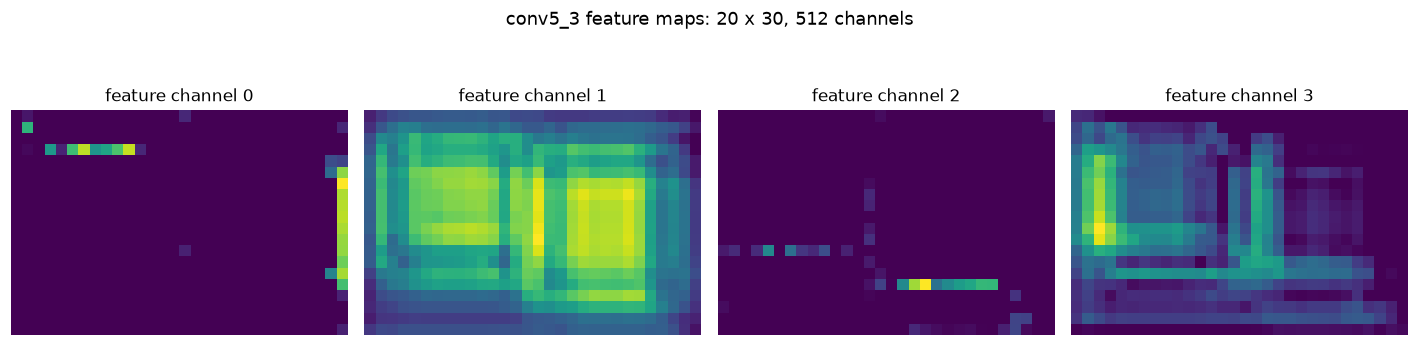

每个空间位置对应原图 16x16 的区域；512 个通道是共享特征。


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, channel in zip(axes, [0, 1, 2, 3]):
    ax.imshow(feat[0, channel].detach().cpu(), cmap="viridis")
    ax.set_title(f"feature channel {channel}")
    ax.axis("off")
fig.suptitle("conv5_3 feature maps: 20 x 30, 512 channels", y=1.02)
plt.tight_layout()
plt.show()

print("每个空间位置对应原图 16x16 的区域；512 个通道是共享特征。")

### 观察点

- 输入 `[1, 3, 320, 480]` 经过 4 次池化变成 `[1, 512, 20, 30]`；
- RPN 和 RoI head 都建立在这同一张 `[1, 512, 20, 30]` 特征图上，这就是论文说的 **shared convolutional features**；
- backbone 只到 `conv5_3`，没有 VGG 最后的 `pool5`，所以 stride 是 16 而不是 32。

## 4. Stage 2：Anchor 生成器

RPN 不直接回归任意框，而是在每个 feature map 位置预置 $A$ 个 anchor，让网络判断“这个 anchor 里有没有物体”，并回归“它离 GT 有多远”。

对每个位置 $(x,y)$，anchor 的中心是：

$$
(x\cdot s + s/2,\; y\cdot s + s/2)
$$

其中 $s=16$ 是 stride。每个 anchor 的面积是 `scale²`，高宽比是 `ratio`：

$$
w = \text{scale}\sqrt{1/\text{ratio}},\qquad
h = \text{scale}\sqrt{\text{ratio}}
$$

In [12]:
class AnchorGenerator(nn.Module):
    """
    在每个 feature map 位置生成 A = len(scales) * len(ratios) 个 anchor。
    论文默认：3 种面积 (128^2, 256^2, 512^2) × 3 种长宽比 = 9 个 anchor。
    """

    def __init__(self, scales: Sequence[int], ratios: Sequence[float], stride: int) -> None:
        super().__init__()
        self.scales = tuple(scales)
        self.ratios = tuple(ratios)
        self.stride = stride
        self.register_buffer(
            "_base_anchors", self._build_base_anchors(), persistent=False
        )

    def _build_base_anchors(self) -> torch.Tensor:
        anchors = []
        for scale in self.scales:
            for ratio in self.ratios:
                # 面积 = scale^2，高宽比 = ratio
                width = scale * math.sqrt(1.0 / ratio)
                height = scale * math.sqrt(ratio)
                anchors.append(
                    [-width / 2.0, -height / 2.0, width / 2.0, height / 2.0]
                )
        return torch.tensor(anchors, dtype=torch.float32)

    def forward(
        self, height: int, width: int, device: torch.device, dtype: torch.dtype
    ) -> torch.Tensor:
        base_anchors = self._base_anchors.to(device=device, dtype=dtype)
        shift_x = (
            torch.arange(width, device=device, dtype=dtype) + 0.5
        ) * self.stride
        shift_y = (
            torch.arange(height, device=device, dtype=dtype) + 0.5
        ) * self.stride
        shift_y, shift_x = torch.meshgrid(shift_y, shift_x, indexing="ij")
        shifts = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=-1).reshape(-1, 4)

        # [H*W, 1, 4] + [1, A, 4] -> [H*W*A, 4]
        anchors = (shifts[:, None, :] + base_anchors[None, :, :]).reshape(-1, 4)
        return anchors

In [13]:
anchor_gen = AnchorGenerator(
    scales=cfg.anchor_scales,
    ratios=cfg.anchor_ratios,
    stride=cfg.anchor_stride,
).to(DEVICE)

hf, wf = feat.shape[-2:]
anchors = anchor_gen(hf, wf, feat.device, feat.dtype)

num_anchors_per_location = len(cfg.anchor_scales) * len(cfg.anchor_ratios)
print("feature map       :", (hf, wf))
print("anchors per pixel :", num_anchors_per_location)
print("total anchors     :", tuple(anchors.shape))
print("expected          :", hf * wf * num_anchors_per_location)
print("\nfirst 9 anchors (one location):")
print(anchors[:9].cpu())

feature map       : (20, 30)
anchors per pixel : 9
total anchors     : (5400, 4)
expected          : 5400

first 9 anchors (one location):
tensor([[ -82.510,  -37.255,   98.510,   53.255],
        [ -56.000,  -56.000,   72.000,   72.000],
        [ -37.255,  -82.510,   53.255,   98.510],
        [-173.019,  -82.510,  189.019,   98.510],
        [-120.000, -120.000,  136.000,  136.000],
        [ -82.510, -173.019,   98.510,  189.019],
        [-354.039, -173.019,  370.039,  189.019],
        [-248.000, -248.000,  264.000,  264.000],
        [-173.019, -354.039,  189.019,  370.039]])


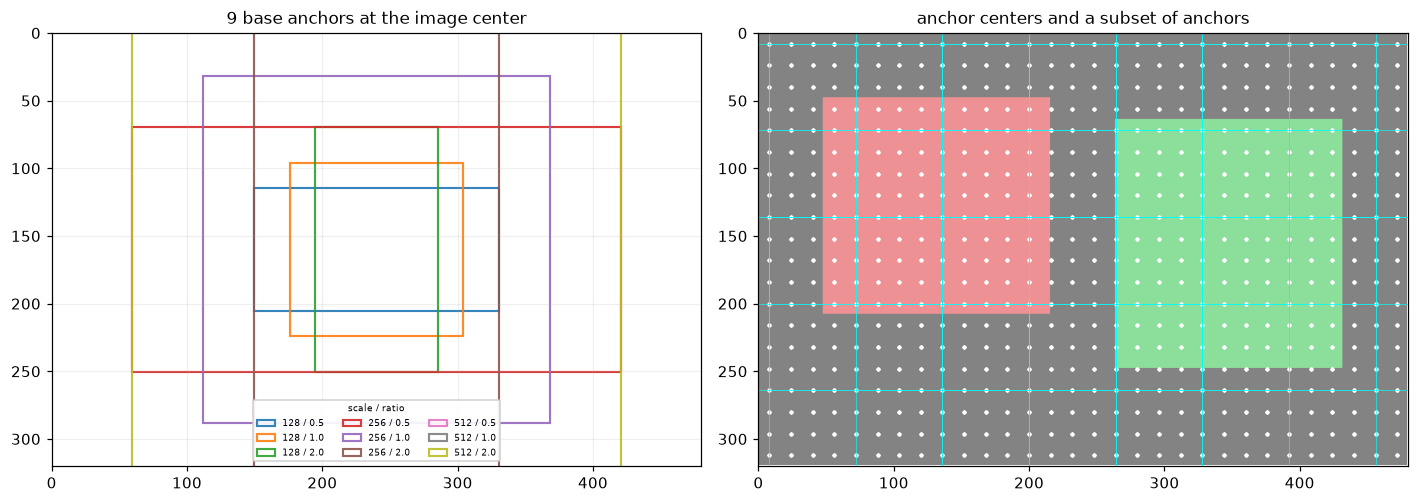

anchor width  range: 90.5096664428711 ~ 724.0773315429688
anchor height range: 90.5096664428711 ~ 724.0773315429688


In [14]:
base = anchor_gen._base_anchors.cpu()
colors = plt.cm.tab10.colors

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# 左图：同一个中心点上的 9 个 anchor
ax = axes[0]
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
center_shift = torch.tensor([W / 2, H / 2, W / 2, H / 2])
for i, box in enumerate(base):
    scale = cfg.anchor_scales[i // len(cfg.anchor_ratios)]
    ratio = cfg.anchor_ratios[i % len(cfg.anchor_ratios)]
    draw_box(
        ax,
        box + center_shift,
        color=colors[i],
        linewidth=1.4,
        label=f"{scale} / {ratio}",
    )
ax.legend(
    loc="lower center",
    ncol=3,
    fontsize=6,
    framealpha=0.9,
    title="scale / ratio",
    title_fontsize=6,
)
ax.set_title("9 base anchors at the image center")

# 右图：所有 anchor 的中心，以及每隔 4 个位置画一个 256/1.0 anchor
ax = axes[1]
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_aspect("equal")
ax.imshow(to_numpy_image(image), alpha=0.55)

centers = anchors.reshape(hf, wf, num_anchors_per_location, 4)
cx = (centers[..., 0] + centers[..., 2]) / 2
cy = (centers[..., 1] + centers[..., 3]) / 2
ax.scatter(cx.reshape(-1).cpu(), cy.reshape(-1).cpu(), s=2, c="white", alpha=0.7)

for yy in range(0, hf, 4):
    for xx in range(0, wf, 4):
        idx = (yy * wf + xx) * num_anchors_per_location + 4  # 256 / 1.0
        draw_box(ax, anchors[idx].cpu(), color="cyan", linewidth=0.6, alpha=0.45)
ax.set_title("anchor centers and a subset of anchors")

plt.tight_layout()
plt.show()

print("anchor width  range:", (base[:, 2] - base[:, 0]).min().item(),
      "~", (base[:, 2] - base[:, 0]).max().item())
print("anchor height range:", (base[:, 3] - base[:, 1]).min().item(),
      "~", (base[:, 3] - base[:, 1]).max().item())

### 观察点

- `anchors.shape == (20*30*9, 4) == (5400, 4)`；
- 9 个 anchor 的中心相同，但面积和长宽比不同；
- 这些 anchor 在整张图上滑动，因此 RPN 只需要学习“相对 anchor 的偏移”，而不需要从零学习框的位置；
- 这正是论文能够用 **卷积** 高效生成 proposals 的原因。

## 5. Stage 3：RPN（Region Proposal Network）

RPN 是 Faster R-CNN 的核心创新。它在共享特征图上加一个 $3\times3$ 卷积，然后分成两条 $1\times1$ 卷积分支：

```text
feature [1, 512, 20, 30]
   │
   └─ 3x3 conv, 512
        ├─ 1x1 conv -> 2A scores (background / foreground)
        └─ 1x1 conv -> 4A deltas (dx, dy, dw, dh)
```

RPN 的训练目标不是直接输出最终检测，而是输出“可能是物体的区域”。这些区域再交给 RoI head 做精细分类和回归。

In [15]:
class RPN(nn.Module):
    """
    RPN 在共享 feature map 的每个位置上预测：
      - 每个 anchor 是前景/背景的 2 个分数；
      - 每个 anchor 相对 GT 的 4 个回归偏移。
    然后 decode + NMS 得到 proposal。
    """

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.cfg = cfg
        self.num_anchors = len(cfg.anchor_scales) * len(cfg.anchor_ratios)

        # 论文：在共享特征上接一个 3x3 conv，再分两路 1x1 conv
        self.conv = nn.Conv2d(
            cfg.backbone_channels, cfg.rpn_channels, kernel_size=3, padding=1
        )
        self.cls_logits = nn.Conv2d(
            cfg.rpn_channels, self.num_anchors * 2, kernel_size=1
        )
        self.bbox_pred = nn.Conv2d(
            cfg.rpn_channels, self.num_anchors * 4, kernel_size=1
        )
        self.anchor_generator = AnchorGenerator(
            cfg.anchor_scales, cfg.anchor_ratios, cfg.anchor_stride
        )
        self._init_weights()

    def _init_weights(self) -> None:
        nn.init.kaiming_normal_(self.conv.weight, mode="fan_out", nonlinearity="relu")
        nn.init.zeros_(self.conv.bias)
        for layer in (self.cls_logits, self.bbox_pred):
            nn.init.normal_(layer.weight, std=0.01)
            nn.init.zeros_(layer.bias)

    def forward(
        self, features: torch.Tensor
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        返回：
            cls_logits: [N, H*W*A, 2]
            bbox_pred:  [N, H*W*A, 4]
            anchors:    [H*W*A, 4]
        """
        x = F.relu(self.conv(features), inplace=True)
        batch_size, _, height, width = x.shape

        # [N, 2A, H, W] -> [N, H, W, 2A] -> [N, H*W*A, 2]
        cls_logits = self.cls_logits(x)
        cls_logits = cls_logits.permute(0, 2, 3, 1).reshape(batch_size, -1, 2)

        # [N, 4A, H, W] -> [N, H*W*A, 4]
        bbox_pred = self.bbox_pred(x)
        bbox_pred = bbox_pred.permute(0, 2, 3, 1).reshape(batch_size, -1, 4)

        anchors = self.anchor_generator(
            height, width, features.device, features.dtype
        )
        return cls_logits, bbox_pred, anchors

    @torch.no_grad()
    def generate_proposals(
        self,
        cls_logits: torch.Tensor,
        bbox_pred: torch.Tensor,
        anchors: torch.Tensor,
        image_sizes: Sequence[Tuple[int, int]],
        pre_nms_top_n: int,
        post_nms_top_n: int,
    ) -> List[torch.Tensor]:
        """
        RPN 的推理过程：
            scores -> decode deltas -> clip -> 取 top-N -> NMS -> 取 top-M
        返回每个 proposal 的 xyxy 坐标（原图尺度）。
        """
        objectness = cls_logits.softmax(dim=-1)[..., 1]  # [N, H*W*A]
        proposals: List[torch.Tensor] = []

        for image_idx, image_size in enumerate(image_sizes):
            boxes = decode_boxes(anchors, bbox_pred[image_idx])
            boxes = clip_boxes(boxes, image_size)
            scores = objectness[image_idx]

            # 去掉裁剪后宽/高为 0 的框
            valid = (boxes[:, 2] > boxes[:, 0]) & (boxes[:, 3] > boxes[:, 1])
            boxes, scores = boxes[valid], scores[valid]

            if boxes.numel() == 0:
                proposals.append(boxes.new_zeros((0, 4)))
                continue

            k = min(pre_nms_top_n, scores.numel())
            scores, order = scores.topk(k, sorted=True)
            boxes = boxes[order]

            keep = nms(boxes, scores, self.cfg.rpn_nms_thresh)
            keep = keep[:post_nms_top_n]
            proposals.append(boxes[keep])

        return proposals

In [16]:
rpn = RPN(cfg).to(DEVICE).eval()

with torch.no_grad():
    rpn_cls, rpn_reg, rpn_anchors = rpn(feat)

print("RPN cls logits :", tuple(rpn_cls.shape))
print("RPN box deltas :", tuple(rpn_reg.shape))
print("RPN anchors    :", tuple(rpn_anchors.shape))
print()
print("每个位置的 anchor 数 A :", rpn.num_anchors)
print("H*W*A                 :", hf * wf * rpn.num_anchors)
print("cls 的 2 代表         : [background, foreground]")
print("reg 的 4 代表         : [dx, dy, dw, dh]")

RPN cls logits : (1, 5400, 2)
RPN box deltas : (1, 5400, 4)
RPN anchors    : (5400, 4)

每个位置的 anchor 数 A : 9
H*W*A                 : 5400
cls 的 2 代表         : [background, foreground]
reg 的 4 代表         : [dx, dy, dw, dh]


proposals shape : (300, 4)
proposal count  : 300 (上限 = 300 )

前 5 个 proposal (xyxy):
tensor([[136.783, 105.882, 264.869, 232.999],
        [136.861,  58.064, 264.742, 185.129],
        [ 89.063, 105.905, 216.928, 232.597],
        [ 40.764, 121.560, 168.616, 248.257],
        [154.015,   0.000, 244.888, 177.287]])


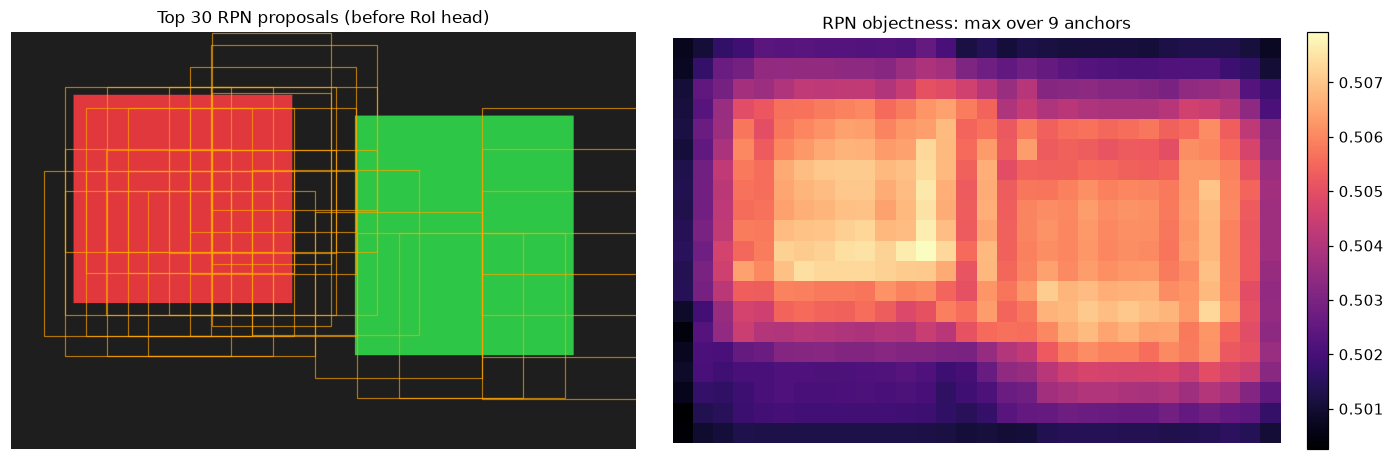

随机权重下 proposal 的分数和位置都没有语义，这里只看形状和流程。


In [17]:
with torch.no_grad():
    proposals = rpn.generate_proposals(
        rpn_cls,
        rpn_reg,
        rpn_anchors,
        image_sizes=[(H, W)],
        pre_nms_top_n=cfg.rpn_pre_nms_top_n_test,
        post_nms_top_n=cfg.rpn_post_nms_top_n_test,
    )

p = proposals[0]
print("proposals shape :", tuple(p.shape))
print("proposal count  :", p.shape[0], "(上限 =", cfg.rpn_post_nms_top_n_test, ")")
print("\n前 5 个 proposal (xyxy):")
print(p[:5].cpu())

objectness = rpn_cls.softmax(dim=-1)[..., 1]
obj_map = objectness.reshape(hf, wf, rpn.num_anchors).max(dim=-1).values

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.imshow(to_numpy_image(image))
topk = min(30, p.shape[0])
for box in p[:topk].cpu():
    draw_box(ax, box, color="orange", linewidth=0.8, alpha=0.65)
ax.set_title(f"Top {topk} RPN proposals (before RoI head)")
ax.axis("off")

ax = axes[1]
im = ax.imshow(obj_map.detach().cpu(), cmap="magma")
ax.set_title("RPN objectness: max over 9 anchors")
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("随机权重下 proposal 的分数和位置都没有语义，这里只看形状和流程。")

### 观察点

- `rpn_cls` 的形状是 `[1, 5400, 2]`：5400 个 anchor，每个 2 个分数；
- `rpn_reg` 的形状是 `[1, 5400, 4]`：每个 anchor 4 个偏移；
- `generate_proposals` 做了四件事：`decode -> clip -> top-N -> NMS`；
- 输出的 proposal 已经是原图坐标，可以直接交给 RoI pooling。

## 6. Stage 4：RoI head（Fast R-CNN 检测头）

RPN 给出的 proposal 大小不一，但后面的全连接层要求固定维度。RoI pooling 把每个 proposal 映射到 feature map 上，再池化成固定的 $7\times7$：

```text
proposal (任意大小)
   │  按 spatial_scale = 1/16 映射到 feature map
   ▼
RoI pooling 7x7  -> [K, 512, 7, 7]
   │  flatten
   ▼
FC6 4096 -> FC7 4096
   ├─ FC num_classes      分类
   └─ FC num_classes * 4  逐类别回归
```

In [18]:
class ROIHead(nn.Module):
    """
    Fast R-CNN 的 head：
        RoI pooling 7x7 -> flatten -> FC6 -> FC7
        -> 分类分数 [K, num_classes]
        -> 逐类别边框偏移 [K, num_classes * 4]
    """

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.cfg = cfg
        pooled_dim = cfg.backbone_channels * cfg.roi_output_size * cfg.roi_output_size

        self.fc6 = nn.Linear(pooled_dim, 4096)
        self.fc7 = nn.Linear(4096, 4096)
        self.cls_score = nn.Linear(4096, cfg.num_classes)
        self.bbox_pred = nn.Linear(4096, cfg.num_classes * 4)
        self._init_weights()

    def _init_weights(self) -> None:
        for layer in (self.fc6, self.fc7, self.cls_score):
            nn.init.normal_(layer.weight, std=0.01)
            nn.init.zeros_(layer.bias)
        # 回归头初始化为 0：训练开始时预测框等于 proposal
        nn.init.zeros_(self.bbox_pred.weight)
        nn.init.zeros_(self.bbox_pred.bias)

    def forward(
        self, features: torch.Tensor, rois: torch.Tensor
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        features: [N, 512, Hf, Wf]
        rois:     [K, 5]，每行为 [batch_index, x1, y1, x2, y2]
        """
        pooled = roi_pool(
            features,
            rois,
            output_size=(self.cfg.roi_output_size, self.cfg.roi_output_size),
            spatial_scale=self.cfg.spatial_scale,
        )  # [K, 512, 7, 7]

        x = pooled.flatten(1)
        x = F.relu(self.fc6(x), inplace=True)
        x = F.dropout(x, p=0.5, training=self.training)
        x = F.relu(self.fc7(x), inplace=True)
        x = F.dropout(x, p=0.5, training=self.training)

        return self.cls_score(x), self.bbox_pred(x)

In [19]:
roi_head = ROIHead(cfg).to(DEVICE).eval()

boxes = proposals[0][:16]
rois = torch.cat(
    [torch.zeros((boxes.shape[0], 1), device=DEVICE, dtype=boxes.dtype), boxes],
    dim=1,
)

with torch.no_grad():
    pooled = roi_pool(
        feat,
        rois,
        output_size=(cfg.roi_output_size, cfg.roi_output_size),
        spatial_scale=cfg.spatial_scale,
    )
    cls_logits, bbox_pred = roi_head(feat, rois)

print("proposal boxes :", tuple(boxes.shape))
print("rois [K,5]     :", tuple(rois.shape), "  (第 0 列是 batch index)")
print("pooled feature :", tuple(pooled.shape))
print("class logits   :", tuple(cls_logits.shape))
print("bbox offsets   :", tuple(bbox_pred.shape))
print()
print("K=16, C=512, 7x7 -> flatten 后是", 512 * 7 * 7, "维")

proposal boxes : (16, 4)
rois [K,5]     : (16, 5)   (第 0 列是 batch index)
pooled feature : (16, 512, 7, 7)
class logits   : (16, 21)
bbox offsets   : (16, 84)

K=16, C=512, 7x7 -> flatten 后是 25088 维


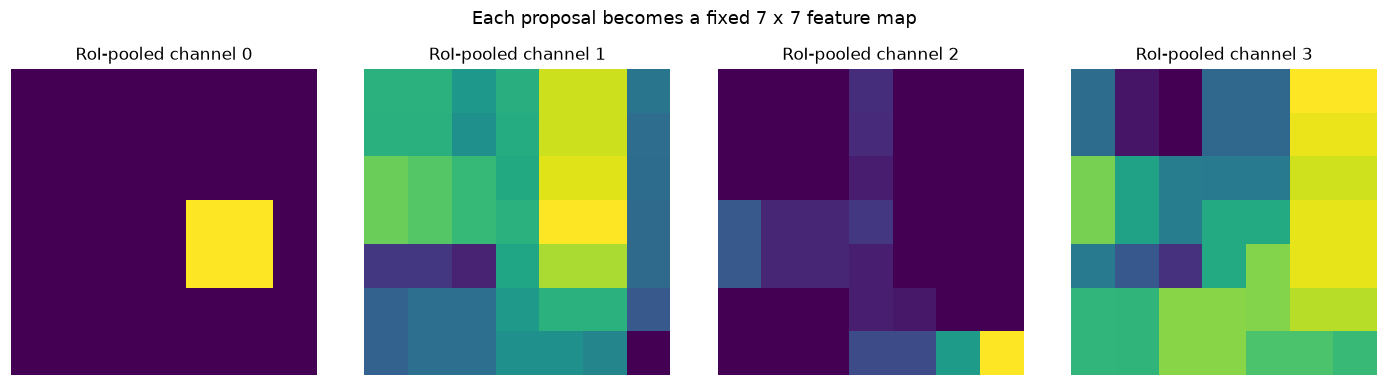

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, channel in zip(axes, [0, 1, 2, 3]):
    ax.imshow(pooled[0, channel].detach().cpu(), cmap="viridis")
    ax.set_title(f"RoI-pooled channel {channel}")
    ax.axis("off")
fig.suptitle("Each proposal becomes a fixed 7 x 7 feature map", y=1.02)
plt.tight_layout()
plt.show()

### 观察点

- 输入 16 个 proposal，输出 16 组分类分数和回归偏移；
- 不管 proposal 在原图里多大，`pooled` 都是 `[16, 512, 7, 7]`；
- `bbox_pred` 有 `num_classes * 4` 个通道：每个类别都有自己的回归器，这是 Fast R-CNN 的 **per-class bounding-box regression**；
- 原论文用的是 RoI max pooling；现代实现常用 RoIAlign（去掉量化误差），本 notebook 为对照论文使用 `roi_pool`。

In [21]:
# 释放前面阶段的模型，给完整模型腾出内存
del backbone, rpn, roi_head, feat, pooled
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("stage models released")

stage models released


## 7. Stage 5：组装完整模型

下面这一格是完整的 `FasterRCNN` 类，比较长，因为它除了三个子模块，还包含：

1. **训练时的标签分配**：anchor 正负样本、RoI 正负样本；
2. **四个损失**：RPN 分类/回归，RoI 分类/回归；
3. **推理时的后处理**：逐类别解码、分数阈值、NMS、top-100。

可以先直接运行，再回到上面的 Stage 1–4 对照每个子模块。

In [22]:
class FasterRCNN(nn.Module):
    def __init__(
        self,
        cfg: Optional[Config] = None,
        pretrained_backbone: bool = False,
    ) -> None:
        super().__init__()
        self.cfg = cfg or Config()
        self.backbone = VGG16Backbone(pretrained=pretrained_backbone)
        self.rpn = RPN(self.cfg)
        self.roi_heads = ROIHead(self.cfg)

    # ------------------------- 训练：标签分配与损失 -------------------------
    def _anchor_targets(
        self,
        anchors: torch.Tensor,
        target: Dict[str, torch.Tensor],
        image_size: Tuple[int, int],
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        RPN 的 anchor 标签：
          - 与某个 GT 的 IoU 最大，或 IoU >= 0.7 -> 正样本
          - IoU < 0.3 -> 负样本
          - 其余（0.3 ~ 0.7）忽略
          - 位于图像外的 anchor 忽略
        """
        gt_boxes = target["boxes"].to(device=anchors.device, dtype=anchors.dtype)
        num_anchors = anchors.shape[0]
        labels = anchors.new_full((num_anchors,), -1.0)
        bbox_targets = anchors.new_zeros((num_anchors, 4))

        height, width = image_size
        centers_x = 0.5 * (anchors[:, 0] + anchors[:, 2])
        centers_y = 0.5 * (anchors[:, 1] + anchors[:, 3])
        inside = (
            (centers_x >= 0)
            & (centers_x <= width)
            & (centers_y >= 0)
            & (centers_y <= height)
        )

        if gt_boxes.numel() == 0:
            labels[inside] = 0.0
            return labels, bbox_targets

        ious = box_iou(anchors, gt_boxes)             # [num_anchors, num_gt]
        max_iou, matched_gt = ious.max(dim=1)

        labels[max_iou >= self.cfg.rpn_positive_thresh] = 1.0
        labels[max_iou < self.cfg.rpn_negative_thresh] = 0.0

        # 每个 GT 至少有一个 anchor 负责它（论文中的 "best anchor" 规则）
        best_anchor = ious.argmax(dim=0)              # [num_gt]
        labels[best_anchor] = 1.0
        matched_gt[best_anchor] = torch.arange(
            gt_boxes.shape[0], device=anchors.device
        )

        labels[~inside] = -1.0
        bbox_targets = encode_boxes(gt_boxes[matched_gt], anchors)
        return labels, bbox_targets

    def _rpn_losses(
        self,
        rpn_cls: torch.Tensor,
        rpn_reg: torch.Tensor,
        anchors: torch.Tensor,
        targets: Sequence[Dict[str, torch.Tensor]],
        image_sizes: Sequence[Tuple[int, int]],
    ) -> Dict[str, torch.Tensor]:
        total_cls = rpn_cls.sum() * 0.0
        total_box = rpn_reg.sum() * 0.0

        for i, (target, image_size) in enumerate(zip(targets, image_sizes)):
            labels, bbox_targets = self._anchor_targets(anchors, target, image_size)
            sampled = sample_indices(
                labels, self.cfg.rpn_batch_size, self.cfg.rpn_positive_fraction
            )
            if sampled.numel() == 0:
                continue

            target_labels = (labels[sampled] > 0).to(dtype=rpn_cls.dtype)
            logits = rpn_cls[i][sampled, 1]
            total_cls = total_cls + F.binary_cross_entropy_with_logits(
                logits, target_labels
            )

            positive = target_labels > 0
            if positive.any():
                total_box = total_box + F.smooth_l1_loss(
                    rpn_reg[i][sampled][positive],
                    bbox_targets[sampled][positive],
                    beta=1.0 / 9.0,
                    reduction="sum",
                ) / max(1, int(positive.sum()))

        num_images = max(1, len(targets))
        return {
            "loss_rpn_cls": total_cls / num_images,
            "loss_rpn_box": total_box / num_images,
        }

    def _sample_rois(
        self,
        proposals: Sequence[torch.Tensor],
        targets: Sequence[Dict[str, torch.Tensor]],
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Fast R-CNN 的 RoI 采样：
          - IoU >= 0.5 -> 正样本，类别取对应 GT 的类别
          - 0.1 <= IoU < 0.5 -> 背景（类别 0）
          - IoU < 0.1 -> 忽略
        实现中把 GT 框也加入候选池，保证每个 batch 一定有正样本。
        """
        all_rois: List[torch.Tensor] = []
        all_labels: List[torch.Tensor] = []
        all_bbox_targets: List[torch.Tensor] = []

        for image_idx, (proposal, target) in enumerate(zip(proposals, targets)):
            gt_boxes = target["boxes"].to(
                device=proposal.device, dtype=proposal.dtype
            )
            gt_labels = target["labels"].to(device=proposal.device)
            if gt_boxes.numel() == 0:
                continue

            candidates = torch.cat([proposal, gt_boxes], dim=0)
            ious = box_iou(candidates, gt_boxes)
            max_iou, matched_gt = ious.max(dim=1)

            labels = torch.full(
                (candidates.shape[0],), -1, dtype=torch.long, device=proposal.device
            )
            labels[max_iou >= self.cfg.roi_positive_thresh] = gt_labels[
                matched_gt[max_iou >= self.cfg.roi_positive_thresh]
            ]
            negative = (max_iou >= self.cfg.roi_negative_thresh) & (
                max_iou < self.cfg.roi_positive_thresh
            )
            labels[negative] = 0

            sampled = sample_indices(
                labels.to(dtype=torch.float32),
                self.cfg.roi_batch_size,
                self.cfg.roi_positive_fraction,
            )
            if sampled.numel() == 0:
                continue

            batch_index = torch.full(
                (sampled.numel(), 1),
                float(image_idx),
                dtype=proposal.dtype,
                device=proposal.device,
            )
            all_rois.append(
                torch.cat([batch_index, candidates[sampled]], dim=1)
            )
            all_labels.append(labels[sampled])
            all_bbox_targets.append(
                encode_boxes(gt_boxes[matched_gt[sampled]], candidates[sampled])
            )

        if not all_rois:
            empty_rois = torch.zeros((0, 5), device=proposals[0].device)
            empty_labels = torch.zeros((0,), dtype=torch.long, device=proposals[0].device)
            empty_targets = torch.zeros((0, 4), device=proposals[0].device)
            return empty_rois, empty_labels, empty_targets

        return (
            torch.cat(all_rois, dim=0),
            torch.cat(all_labels, dim=0),
            torch.cat(all_bbox_targets, dim=0),
        )

    def _roi_losses(
        self,
        cls_logits: torch.Tensor,
        bbox_pred: torch.Tensor,
        labels: torch.Tensor,
        bbox_targets: torch.Tensor,
    ) -> Dict[str, torch.Tensor]:
        cls_loss = F.cross_entropy(cls_logits, labels)
        positive = labels > 0
        if positive.any():
            # 只对"该 RoI 对应类别"的回归分支计算损失
            class_ids = labels[positive]
            pred = bbox_pred[positive].view(-1, self.cfg.num_classes, 4)
            pred = pred[
                torch.arange(pred.shape[0], device=pred.device), class_ids
            ]
            box_loss = F.smooth_l1_loss(
                pred, bbox_targets[positive], beta=1.0 / 9.0, reduction="sum"
            ) / max(1, labels.numel())
        else:
            box_loss = bbox_pred.sum() * 0.0
        return {"loss_roi_cls": cls_loss, "loss_roi_box": box_loss}

    # ------------------------- 推理：逐类别 NMS -------------------------
    def _inference(
        self,
        features: torch.Tensor,
        proposals: Sequence[torch.Tensor],
        image_sizes: Sequence[Tuple[int, int]],
    ) -> List[Dict[str, torch.Tensor]]:
        detections: List[Dict[str, torch.Tensor]] = []

        for image_idx, (boxes, image_size) in enumerate(zip(proposals, image_sizes)):
            if boxes.numel() == 0:
                detections.append(
                    {
                        "boxes": boxes.new_zeros((0, 4)),
                        "labels": torch.zeros((0,), dtype=torch.long, device=boxes.device),
                        "scores": boxes.new_zeros((0,)),
                    }
                )
                continue

            batch_index = torch.full(
                (boxes.shape[0], 1),
                float(image_idx),
                dtype=boxes.dtype,
                device=boxes.device,
            )
            rois = torch.cat([batch_index, boxes], dim=1)
            cls_logits, bbox_pred = self.roi_heads(features, rois)

            scores = F.softmax(cls_logits, dim=1)
            bbox_pred = bbox_pred.view(-1, self.cfg.num_classes, 4)

            out_boxes: List[torch.Tensor] = []
            out_scores: List[torch.Tensor] = []
            out_labels: List[torch.Tensor] = []

            # 背景类 (0) 不输出；每个前景类分别做 NMS
            for class_id in range(1, self.cfg.num_classes):
                class_scores = scores[:, class_id]
                keep = class_scores > self.cfg.score_thresh
                if not keep.any():
                    continue

                class_boxes = decode_boxes(boxes[keep], bbox_pred[keep, class_id])
                class_boxes = clip_boxes(class_boxes, image_size)
                class_scores = class_scores[keep]

                valid = (class_boxes[:, 2] > class_boxes[:, 0]) & (
                    class_boxes[:, 3] > class_boxes[:, 1]
                )
                class_boxes, class_scores = class_boxes[valid], class_scores[valid]
                if class_boxes.numel() == 0:
                    continue

                keep_idx = nms(class_boxes, class_scores, self.cfg.nms_thresh)
                out_boxes.append(class_boxes[keep_idx])
                out_scores.append(class_scores[keep_idx])
                out_labels.append(
                    torch.full(
                        (keep_idx.numel(),),
                        class_id,
                        dtype=torch.long,
                        device=boxes.device,
                    )
                )

            if not out_boxes:
                detections.append(
                    {
                        "boxes": boxes.new_zeros((0, 4)),
                        "labels": torch.zeros((0,), dtype=torch.long, device=boxes.device),
                        "scores": boxes.new_zeros((0,)),
                    }
                )
                continue

            final_boxes = torch.cat(out_boxes, dim=0)
            final_scores = torch.cat(out_scores, dim=0)
            final_labels = torch.cat(out_labels, dim=0)

            k = min(self.cfg.detections_per_img, final_scores.numel())
            final_scores, order = final_scores.topk(k, sorted=True)
            detections.append(
                {
                    "boxes": final_boxes[order],
                    "labels": final_labels[order],
                    "scores": final_scores,
                }
            )

        return detections

    # ------------------------- 前向入口 -------------------------
    def forward(
        self,
        images: Sequence[torch.Tensor],
        targets: Optional[Sequence[Dict[str, torch.Tensor]]] = None,
    ):
        """
        images:  list，每个元素为 [3, H, W]，取值建议归一化到 [0, 1]
        targets: 训练时传入，每个元素为 {"boxes": [G,4], "labels": [G]}（xyxy，原图坐标）
        返回：
            训练模式 -> {"loss_rpn_cls": ..., "loss_rpn_box": ..., ...}
            推理模式 -> list[{"boxes", "labels", "scores"}]
        """
        if self.training and targets is None:
            raise ValueError("训练模式必须提供 targets")
        if targets is not None and len(targets) != len(images):
            raise ValueError("images 和 targets 数量必须一致")

        image_sizes = [(int(image.shape[-2]), int(image.shape[-1])) for image in images]
        for height, width in image_sizes:
            if height % self.cfg.anchor_stride != 0 or width % self.cfg.anchor_stride != 0:
                raise ValueError(
                    f"图像尺寸 ({height}, {width}) 必须能被 "
                    f"{self.cfg.anchor_stride} 整除"
                )

        # 本教学实现假设 batch 内尺寸一致
        features = self.backbone(torch.stack(list(images), dim=0))
        rpn_cls, rpn_reg, anchors = self.rpn(features)

        if self.training:
            proposals = self.rpn.generate_proposals(
                rpn_cls,
                rpn_reg,
                anchors,
                image_sizes,
                pre_nms_top_n=self.cfg.rpn_pre_nms_top_n_train,
                post_nms_top_n=self.cfg.rpn_post_nms_top_n_train,
            )
            losses = self._rpn_losses(
                rpn_cls, rpn_reg, anchors, targets, image_sizes
            )

            rois, roi_labels, roi_bbox_targets = self._sample_rois(proposals, targets)
            if rois.numel() == 0:
                zero = features.sum() * 0.0
                losses["loss_roi_cls"] = zero
                losses["loss_roi_box"] = zero
            else:
                cls_logits, bbox_pred = self.roi_heads(features, rois)
                losses.update(
                    self._roi_losses(
                        cls_logits, bbox_pred, roi_labels, roi_bbox_targets
                    )
                )
            return losses

        proposals = self.rpn.generate_proposals(
            rpn_cls,
            rpn_reg,
            anchors,
            image_sizes,
            pre_nms_top_n=self.cfg.rpn_pre_nms_top_n_test,
            post_nms_top_n=self.cfg.rpn_post_nms_top_n_test,
        )
        return self._inference(features, proposals, image_sizes)

In [23]:
def count_parameters(module: nn.Module) -> int:
    return sum(parameter.numel() for parameter in module.parameters())


def architecture_summary(model: FasterRCNN) -> str:
    cfg = model.cfg
    total = count_parameters(model) / 1e6
    backbone = count_parameters(model.backbone) / 1e6
    rpn = count_parameters(model.rpn) / 1e6
    head = count_parameters(model.roi_heads) / 1e6
    num_anchors = len(cfg.anchor_scales) * len(cfg.anchor_ratios)
    return f"""
================ Faster R-CNN (VGG16) 架构 ================
输入                 : [B, 3, H, W]，H/W 可被 16 整除
共享主干             : VGG16 conv1_1..conv5_3  ->  [B, 512, H/16, W/16]
RPN                  : 3x3 conv({cfg.rpn_channels}) + 1x1 cls/reg
  anchors            : {len(cfg.anchor_scales)} scales x {len(cfg.anchor_ratios)} ratios = {num_anchors}/位置
  cls 输出           : [B, H/16*W/16*{num_anchors}, 2]      (背景/前景)
  reg 输出           : [B, H/16*W/16*{num_anchors}, 4]      (dx,dy,dw,dh)
  proposal           : decode -> clip -> top-N -> NMS -> 约 {cfg.rpn_post_nms_top_n_test} 个
RoI head             : RoI pooling {cfg.roi_output_size}x{cfg.roi_output_size}
  FC6 / FC7          : 4096 / 4096（dropout 0.5）
  分类               : {cfg.num_classes} 类（含背景）
  回归               : {cfg.num_classes * 4} 个偏移（逐类别）
输出                 : 训练 -> 4 个 loss；推理 -> boxes / labels / scores
参数统计             : backbone {backbone:.1f}M | RPN {rpn:.1f}M | RoI head {head:.1f}M | 总计 {total:.1f}M
==========================================================
""".strip()

In [24]:
model = FasterRCNN(cfg).to(DEVICE)
print(architecture_summary(model))
print("\nmodel device:", next(model.parameters()).device)

================ Faster R-CNN (VGG16) 架构 ================
输入                 : [B, 3, H, W]，H/W 可被 16 整除
共享主干             : VGG16 conv1_1..conv5_3  ->  [B, 512, H/16, W/16]
RPN                  : 3x3 conv(512) + 1x1 cls/reg
  anchors            : 3 scales x 3 ratios = 9/位置
  cls 输出           : [B, H/16*W/16*9, 2]      (背景/前景)
  reg 输出           : [B, H/16*W/16*9, 4]      (dx,dy,dw,dh)
  proposal           : decode -> clip -> top-N -> NMS -> 约 300 个
RoI head             : RoI pooling 7x7
  FC6 / FC7          : 4096 / 4096（dropout 0.5）
  分类               : 21 类（含背景）
  回归               : 84 个偏移（逐类别）
输出                 : 训练 -> 4 个 loss；推理 -> boxes / labels / scores
参数统计             : backbone 14.7M | RPN 2.4M | RoI head 120.0M | 总计 137.1M

model device: cuda:0


### 四个 loss 从哪里来？

| Loss | 作用对象 | 监督信号 |
|---|---|---|
| `loss_rpn_cls` | 采样后的 256 个 anchor | anchor 是前景还是背景 |
| `loss_rpn_box` | 正样本 anchor | anchor 到 GT 的 4 个偏移 |
| `loss_roi_cls` | 采样后的 RoI | RoI 的类别（含背景） |
| `loss_roi_box` | 正样本 RoI | RoI 到 GT 的逐类别偏移 |

训练时 RPN 和 RoI head 共享同一个 VGG16 backbone，所以一次反向传播会同时更新三者。这就是“近似联合训练”。

## 8. Stage 6：一次训练前向与反向传播

把合成图送进模型，观察四个 loss，然后做一次 `backward()`，检查梯度是否真的流到了 VGG16、RPN 和 RoI head。

In [25]:
model.train()
images = [image.to(DEVICE)]
targets = [
    {
        "boxes": gt_boxes.to(DEVICE),
        "labels": gt_labels.to(DEVICE),
    }
]

losses = model(images, targets)
for name, value in losses.items():
    print(f"{name:16s}: {value.item():.4f}")

total_loss = sum(losses.values())
print("\ntotal loss      :", round(total_loss.item(), 4))

# 观察 RPN 标签分配的比例（使用 Stage 2 生成的 anchors）
with torch.no_grad():
    anchor_labels, _ = model._anchor_targets(anchors, targets[0], (H, W))
print("RPN anchors     :", anchor_labels.numel())
print("  positive      :", int((anchor_labels == 1).sum()))
print("  negative      :", int((anchor_labels == 0).sum()))
print("  ignored       :", int((anchor_labels == -1).sum()))

loss_rpn_cls    : 0.6939
loss_rpn_box    : 0.7321
loss_roi_cls    : 3.0312
loss_roi_box    : 0.0237

total loss      : 4.481
RPN anchors     : 5400
  positive      : 2
  negative      : 4404
  ignored       : 994


gradient RMS by block:
  backbone  : 5.068e-04
  rpn       : 1.242e-03
  roi_heads : 1.638e-04


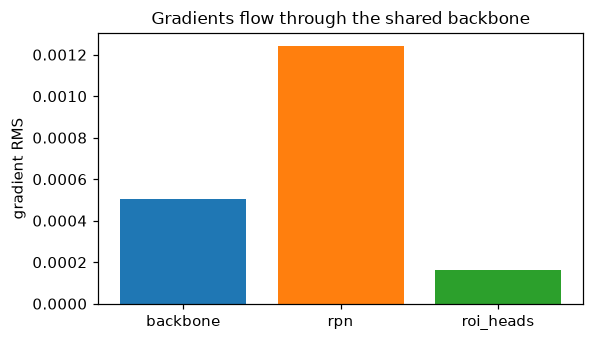

三个模块都拿到了非零梯度，说明共享特征和两阶段 head 在同一次反向传播中联合更新。


In [26]:
model.zero_grad(set_to_none=True)
total_loss.backward()

def grad_rms(prefix: str) -> float:
    grads = [
        p.grad.detach().float()
        for name, p in model.named_parameters()
        if name.startswith(prefix) and p.grad is not None
    ]
    if not grads:
        return 0.0
    sum_sq = sum((g ** 2).sum() for g in grads)
    numel = sum(g.numel() for g in grads)
    return (sum_sq / numel).sqrt().item()

blocks = ["backbone", "rpn", "roi_heads"]
values = [grad_rms(block) for block in blocks]

print("gradient RMS by block:")
for block, value in zip(blocks, values):
    print(f"  {block:10s}: {value:.3e}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(blocks, values, color=["tab:blue", "tab:orange", "tab:green"])
ax.set_ylabel("gradient RMS")
ax.set_title("Gradients flow through the shared backbone")
plt.tight_layout()
plt.show()

print("三个模块都拿到了非零梯度，说明共享特征和两阶段 head 在同一次反向传播中联合更新。")

### 观察点

- 四个 loss 都是标量，训练时通常直接相加；
- RPN 的标签有三种：正样本、负样本、忽略；
- 梯度在 `backbone`、`rpn`、`roi_heads` 三个模块上都存在，说明一次训练会同时更新共享卷积层；
- 这里没有调用 `optimizer.step()`，只是演示反向传播。真实训练还需要优化器、学习率调度和数据加载器。

## 9. Stage 7：推理、逐类别 NMS 与最终检测

推理流程和训练不同：

1. RPN 生成约 300 个 proposal；
2. 所有 proposal 过 RoI head；
3. 对每个前景类，把该类别的偏移解码成框；
4. 按分数过滤，再对每个类别单独做 NMS；
5. 合并所有类别，保留分数最高的 100 个框。

因为是随机权重，下面的框没有检测意义，但可以看到完整的后处理链路。

In [27]:
model.eval()

# 随机初始化时，21 类的 softmax 分数都接近 1/21 ≈ 0.048，
# 默认 score_thresh=0.05 会把所有框都过滤掉。为了观察后处理流程，
# 这里仅在 demo 中把阈值降到 0.01；真实训练后应使用 0.05~0.5。
model.cfg.score_thresh = 0.01

with torch.no_grad():
    detections = model([image.to(DEVICE)])

det = detections[0]
print("score_thresh :", model.cfg.score_thresh)
print("boxes  :", tuple(det["boxes"].shape))
print("labels :", tuple(det["labels"].shape))
print("scores :", tuple(det["scores"].shape))
print()
for box, label, score in list(
    zip(det["boxes"].cpu(), det["labels"].cpu(), det["scores"].cpu())
)[:10]:
    print(
        f"class {int(label):2d}  score {float(score):.4f}  "
        f"box {[round(float(v), 1) for v in box]}"
    )

score_thresh : 0.01
boxes  : (100, 4)
labels : (100,)
scores : (100,)

class 12  score 0.0487  box [153.4, 27.6, 243.9, 209.0]
class 12  score 0.0486  box [24.0, 0.0, 278.2, 225.6]
class 12  score 0.0486  box [121.7, 26.5, 212.0, 208.4]
class 12  score 0.0485  box [118.1, 102.4, 245.0, 231.8]
class 17  score 0.0485  box [182.6, 0.0, 309.9, 104.5]
class 17  score 0.0485  box [182.2, 54.7, 310.0, 183.4]
class 17  score 0.0485  box [149.8, 70.6, 277.1, 199.6]
class 12  score 0.0485  box [73.9, 10.8, 164.2, 192.5]
class  8  score 0.0485  box [9.8, 0.0, 100.7, 176.4]
class 12  score 0.0485  box [134.1, 6.9, 260.9, 136.2]


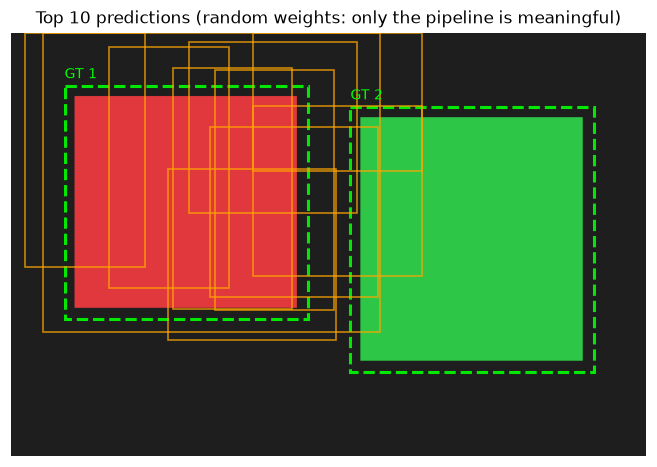

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(to_numpy_image(image))

# GT 用绿色虚线
draw_boxes(ax, gt_boxes, color="lime", linewidth=2.0, linestyle="--")
for box, label in zip(gt_boxes, gt_labels):
    ax.text(
        float(box[0]),
        float(box[1]) - 6,
        f"GT {int(label)}",
        color="lime",
        fontsize=9,
    )

# 预测框用橙色，只画 top-10，避免随机权重下画面过于拥挤
topk = min(10, det["boxes"].shape[0])
for box in det["boxes"][:topk].cpu():
    draw_box(ax, box, color="orange", linewidth=1.1, alpha=0.75)

ax.set_title(
    f"Top {topk} predictions (random weights: only the pipeline is meaningful)"
)
ax.axis("off")
plt.show()

## 10. 复盘：代码与论文的对应关系

| 论文概念 | notebook 中的位置 | 关键张量 |
|---|---|---|
| Shared conv features | Stage 1 `VGG16Backbone` | `[1, 512, 20, 30]` |
| Anchors | Stage 2 `AnchorGenerator` | `[5400, 4]` |
| RPN objectness | Stage 3 `RPN.cls_logits` | `[1, 5400, 2]` |
| RPN box deltas | Stage 3 `RPN.bbox_pred` | `[1, 5400, 4]` |
| Proposals | Stage 3 `generate_proposals` | `[300, 4]` |
| RoI pooling | Stage 4 `roi_pool` | `[K, 512, 7, 7]` |
| Fast R-CNN head | Stage 4 `ROIHead` | `[K, 21]`, `[K, 84]` |
| Training losses | Stage 6 `losses` | 4 个标量 |
| Per-class NMS | Stage 7 `_inference` | `[<=100, 4]` |

### 可以继续做的实验

1. **改 anchor**：把 `anchor_scales` 改成 `(64, 128, 256)`，看 proposal 数量和框的大小如何变化。
2. **改分辨率**：把 `H, W` 改成 `(256, 320)`，观察 feature map 和 anchor 数量的变化。
3. **改阈值**：把 `score_thresh` 从 `0.05` 调到 `0.5`，看最终检测数量如何减少。
4. **换 RoI 层**：把 `roi_pool` 换成 `torchvision.ops.roi_align`，比较两者的坐标量化差异。
5. **加载预训练**：只加载 VGG16 的 ImageNet 权重，再在 VOC 上微调，观察真实检测效果。
6. **对照实现**：阅读 `torchvision.models.detection.fasterrcnn_resnet50_fpn_v2`，比较 ResNet-FPN 版本和本 notebook 的 VGG16 版本。

### 一句话总结

Faster R-CNN 把“找候选框”和“识别候选框”放进同一个网络：

$$
\text{image} \rightarrow \text{shared conv} \rightarrow
\underbrace{\text{RPN}}_{\text{where}} \rightarrow
\underbrace{\text{RoI head}}_{\text{what}} \rightarrow
\text{detections}
$$

RPN 负责 **where**，RoI head 负责 **what**，而两者共享卷积特征，这正是它比 R-CNN/Fast R-CNN 更快的关键。